In [1]:
%pip install -q shap pandas scikit-learn matplotlib


In [2]:
import json
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, make_scorer, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler,
)
SEED = 42
BASE = ["Pclass", "SibSp", "Parch", "Fare"]
NUM = ["Age", "SibSp", "Parch", "Fare"]
CAT = ["Pclass", "Sex", "Embarked"]
DERIVED = ["FamilySize", "FarePerPerson"]
REQUIRED = {"PassengerId", "Survived", "Ticket", "Cabin", *NUM, *CAT}
CORE = ("Base", "Exp-1", "Exp-2", "Exp-3")
CONFIGS = {
    "Exp-1": ("mean", "One-Hot", "Standard", True, False),
    "Exp-2": ("median", "Label", "MinMax", True, True),
    "Exp-3": ("most_frequent", "One-Hot", "Robust", True, True),
    "A-Median": ("median", "One-Hot", "Standard", True, False),
    "A-Mode": ("most_frequent", "One-Hot", "Standard", True, False),
    "A-Label": ("mean", "Label", "Standard", True, False),
    "A-MinMax": ("mean", "One-Hot", "MinMax", True, False),
    "A-Robust": ("mean", "One-Hot", "Robust", True, False),
    "A-NoDerived": ("mean", "One-Hot", "Standard", False, False),
    "A-Top6": ("mean", "One-Hot", "Standard", True, True),
    "A-Exp2-All": ("median", "Label", "MinMax", True, False),
    "A-Exp3-All": ("most_frequent", "One-Hot", "Robust", True, False),
}
SCALERS = {"Standard": StandardScaler, "MinMax": MinMaxScaler, "Robust": RobustScaler}
SCORING = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}
MODELS = ("LR", "RF")
import platform
import hashlib
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sklearn
import shap
from google.colab import files
from IPython.display import display, Image, Markdown

RUN_DIR = Path('/content/titanic_direct')
RUN_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = RUN_DIR / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
print('Python:', platform.python_version(), '| numpy:', np.__version__, '| pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__, '| shap:', shap.__version__)


Python: 3.13.18 | numpy: 2.4.6 | pandas: 2.2.3
scikit-learn: 1.6.1 | shap: 0.54.1


## STEP 01 데이터 준비

Kaggle Titanic의 891개 학습 승객을 대상으로 Survived(사망 0·생존 1)를 예측합니다.
수치형·범주형 변수를 함께 사용합니다. 분석은 개발 데이터에서 수행하고 최종 평가 데이터는 별도로 보관합니다.


In [3]:
print('Kaggle train.csv 한 개를 업로드하세요.')
uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError('train.csv 한 개만 업로드하세요.')
uploaded_name, contents = next(iter(uploaded.items()))
if not uploaded_name.lower().endswith('.csv'):
    raise ValueError('CSV 파일을 업로드하세요.')
TRAIN_FILE = RUN_DIR / 'train.csv'
TRAIN_FILE.write_bytes(contents)
data = pd.read_csv(TRAIN_FILE)
if missing := REQUIRED - set(data):
    raise ValueError(f'필수 열 누락: {sorted(missing)}')
if len(data) < 500 or set(data['Survived'].unique()) != {0, 1}:
    raise ValueError('500개 이상의 표본과 0/1 타깃 Survived가 필요합니다.')
if not data['PassengerId'].is_unique or data[BASE].isna().any().any():
    raise ValueError('PassengerId는 고유해야 하고 Base의 원본 변수에는 결측치가 없어야 합니다.')
x, y = data[NUM + CAT], data['Survived']
train, test, train_y, test_y = train_test_split(x, y, test_size=.2, stratify=y, random_state=SEED)
eda = data.loc[train.index]
print('전체 shape:', data.shape, '| 개발:', train.shape, '| 최종 평가:', test.shape)
display(data.head())
descriptions = {
    'PassengerId':'승객 식별자, 입력 제외', 'Survived':'생존 여부, 예측 타깃',
    'Pclass':'객실 등급, Base는 원본 정수/다른 실험은 범주형', 'Name':'승객 이름, 입력 제외',
    'Sex':'성별, 범주형', 'Age':'나이, 수치형', 'SibSp':'동승 형제자매/배우자 수, 수치형',
    'Parch':'동승 부모/자녀 수, 수치형', 'Ticket':'승선권 번호, 입력 제외',
    'Fare':'기록 운임, 수치형', 'Cabin':'객실 번호, 높은 결측률로 입력 제외',
    'Embarked':'승선항, 범주형',
}
display(pd.DataFrame({'설명':descriptions, 'dtype':data.dtypes.astype(str)}))


Kaggle train.csv 한 개를 업로드하세요.


Saving train.csv to train.csv
전체 shape: (891, 12) | 개발: (712, 7) | 최종 평가: (179, 7)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,설명,dtype
PassengerId,"승객 식별자, 입력 제외",int64
Survived,"생존 여부, 예측 타깃",int64
Pclass,"객실 등급, Base는 원본 정수/다른 실험은 범주형",int64
Name,"승객 이름, 입력 제외",object
Sex,"성별, 범주형",object
Age,"나이, 수치형",float64
SibSp,"동승 형제자매/배우자 수, 수치형",int64
Parch,"동승 부모/자녀 수, 수치형",int64
Ticket,"승선권 번호, 입력 제외",object
Fare,"기록 운임, 수치형",float64


## STEP 02 EDA

개발 데이터의 결측률·이상치·분포·상관관계·타깃 불균형을 확인합니다.

,결측 개수,결측률 %
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,137,19.24
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


,count,observed,low,high
Age,6.0,575.0,-6.0000,66.0000
Fare,91.0,712.0,-26.7605,65.6563


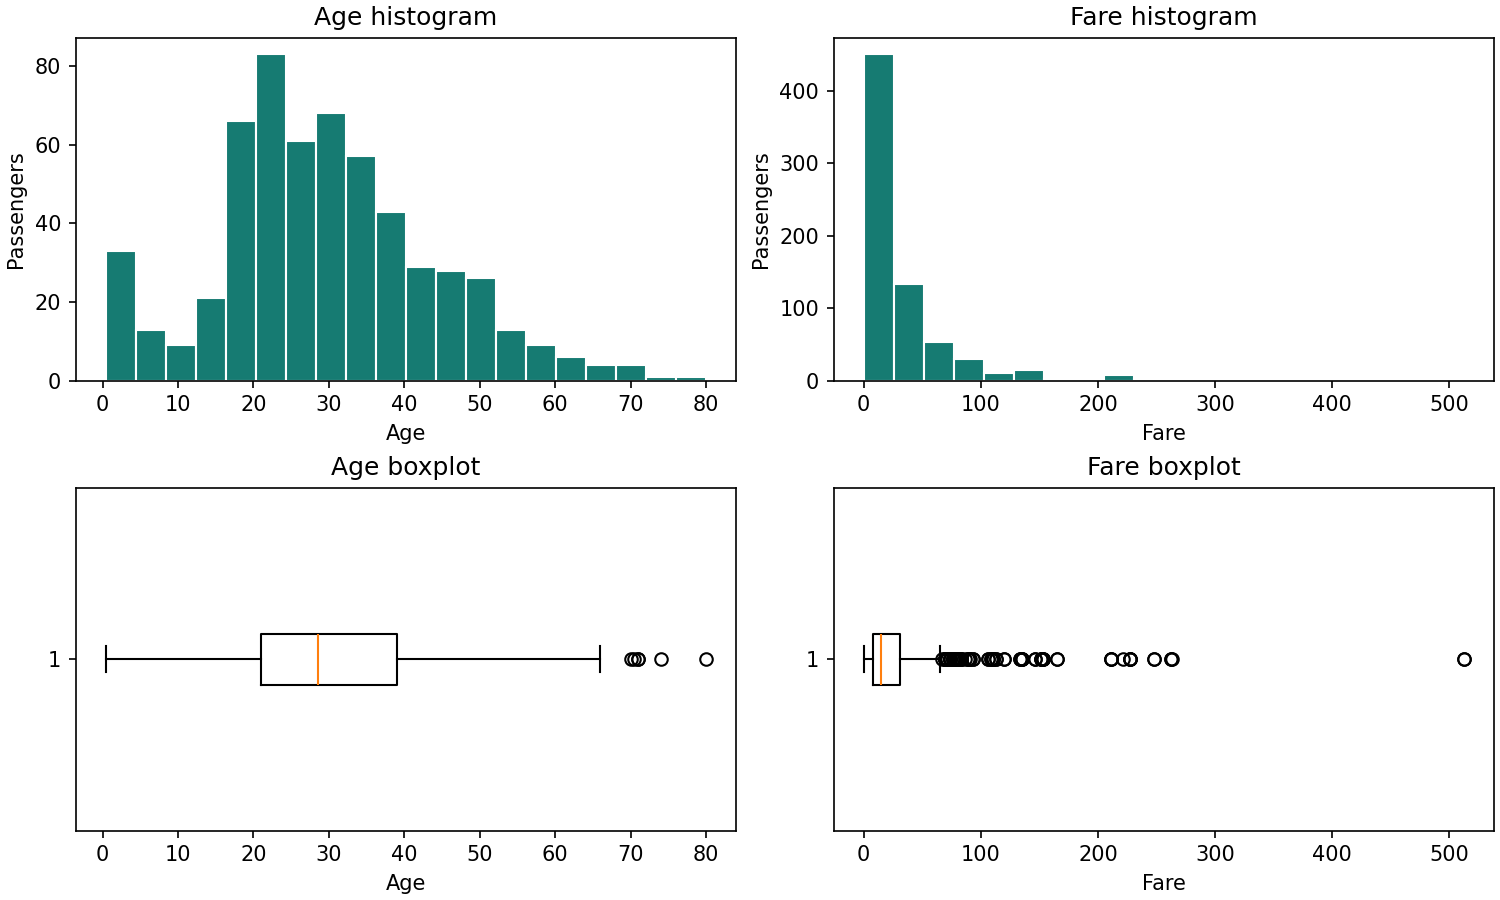

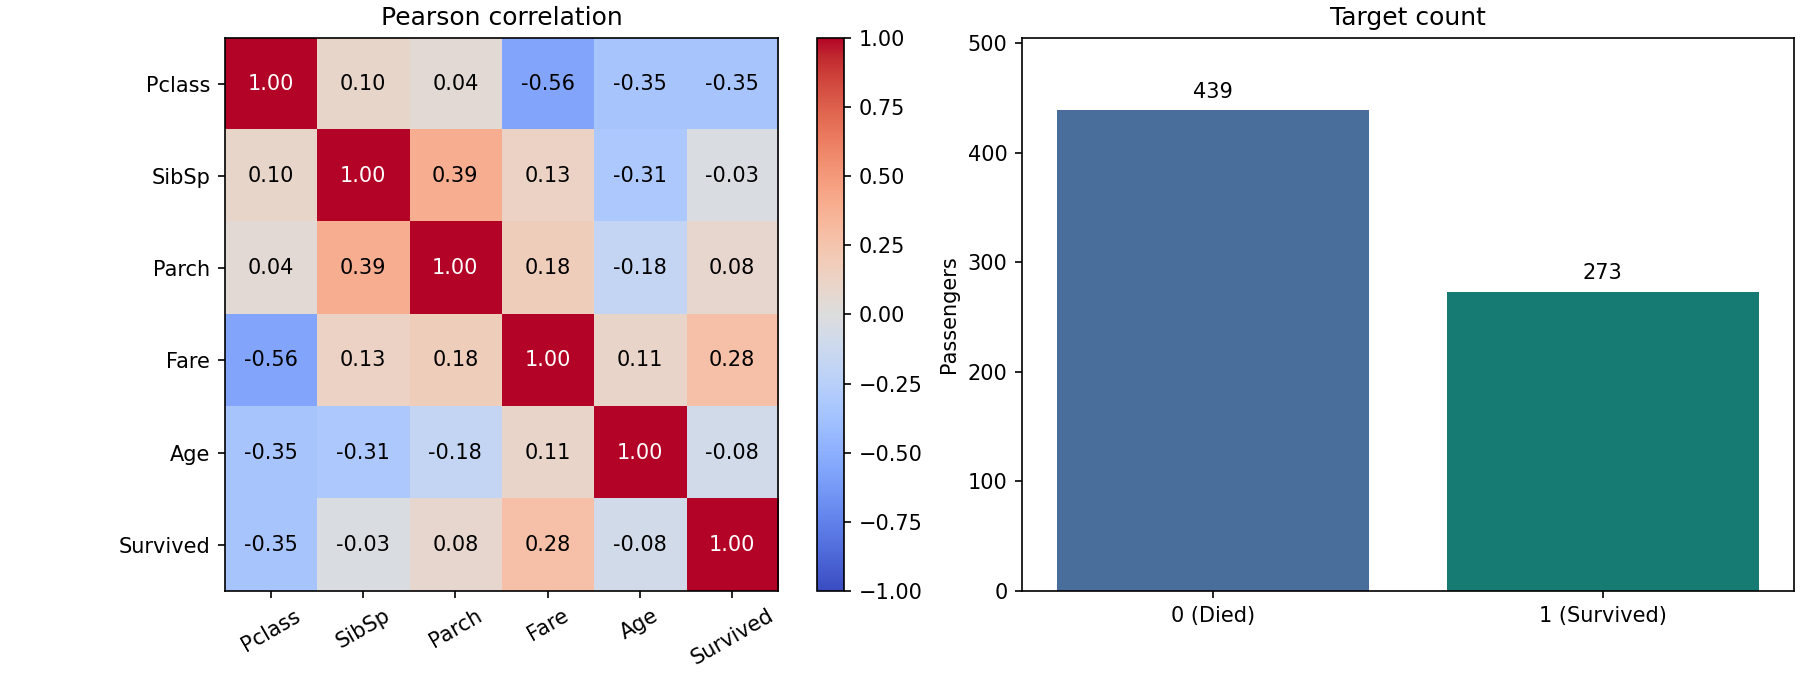

중복 행: 0
개발 데이터 타깃 비율: {0: 0.617, 1: 0.383}
Fare의 큰 값은 IQR 기준으로 탐색하되 모델 입력에서 삭제하지 않습니다.


,생존율
Sex,
female,0.743083
male,0.185185


,생존율
Pclass,
1,0.649123
2,0.446667
3,0.242967


In [4]:
def outlier_counts(eda):
    result = {}
    for column in ("Age", "Fare"):
        observed = eda[column].dropna()
        q1, q3 = observed.quantile([.25, .75])
        spread = q3 - q1
        low, high = q1 - 1.5 * spread, q3 + 1.5 * spread
        result[column] = {
            "count": int(((observed < low) | (observed > high)).sum()), "observed": len(observed),
            "low": float(low), "high": float(high),
        }
    return result

def save_eda_plots(eda, out):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
    for i, column in enumerate(("Age", "Fare")):
        values = eda[column].dropna()
        axes[0, i].hist(values, bins=20, color="#167b72", edgecolor="white")
        axes[0, i].set(xlabel=column, ylabel="Passengers", title=f"{column} histogram")
        axes[1, i].boxplot(values, vert=False)
        axes[1, i].set(xlabel=column, title=f"{column} boxplot")
    fig.savefig(out / "eda_distributions.png", dpi=150)
    plt.close(fig)

    columns = ["Pclass", "SibSp", "Parch", "Fare", "Age", "Survived"]
    corr = eda[columns].corr()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    ax = axes[0]
    heat = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    for i in range(len(columns)):
        for j in range(len(columns)):
            value = corr.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                    color="white" if abs(value) > .65 else "black")
    ax.set(xticks=range(len(columns)), xticklabels=columns, yticks=range(len(columns)),
           yticklabels=columns, title="Pearson correlation")
    ax.tick_params(axis="x", rotation=30)
    fig.colorbar(heat, ax=ax)
    counts = eda["Survived"].value_counts().reindex([0, 1])
    bars = axes[1].bar(["0 (Died)", "1 (Survived)"], counts, color=["#496e9b", "#167b72"])
    axes[1].bar_label(bars, padding=4)
    axes[1].set(ylabel="Passengers", title="Target count", ylim=(0, counts.max() * 1.15))
    fig.savefig(out / "eda_relationships.png", dpi=150)
    plt.close(fig)
display(pd.DataFrame({'결측 개수': eda.isna().sum(), '결측률 %': eda.isna().mean()*100}).round(2))
outliers = outlier_counts(eda)
display(pd.DataFrame(outliers).T)
save_eda_plots(eda, RESULTS_DIR)
display(Image(filename=str(RESULTS_DIR / 'eda_distributions.png')))
display(Image(filename=str(RESULTS_DIR / 'eda_relationships.png')))
print('중복 행:', eda.duplicated().sum())
print('개발 데이터 타깃 비율:', eda['Survived'].value_counts(normalize=True).round(3).to_dict())
print('Fare의 큰 값은 IQR 기준으로 탐색하되 모델 입력에서 삭제하지 않습니다.')
display(eda.groupby('Sex')['Survived'].mean().rename('생존율').to_frame())
display(eda.groupby('Pclass')['Survived'].mean().rename('생존율').to_frame())


## STEP 03 특성 공학 파이프라인

수치형 결측은 평균·중앙값·최빈값, 범주형 인코딩은 One-Hot·Ordinal,
스케일링은 Standard·MinMax·Robust를 비교합니다. 범주형 결측은 최빈값으로 채웁니다.
FamilySize = SibSp + Parch + 1, FarePerPerson = Fare / FamilySize를 만듭니다.
Base는 결측이 없는 Pclass·SibSp·Parch·Fare만 사용하므로 전체 실험과의 차이에는 입력 변수 차이도 포함됩니다.


In [5]:
def add_features(frame):
    size = frame["SibSp"] + frame["Parch"] + 1
    return frame.assign(FamilySize=size, FarePerPerson=frame["Fare"] / size)

def make_pipeline(experiment, model):
    if model == "LR":
        estimator = LogisticRegression(max_iter=2000, random_state=SEED)
    else:
        estimator = RandomForestClassifier(
            n_estimators=48, max_depth=9, min_samples_leaf=3, max_features="sqrt", random_state=SEED,
        )
    if experiment == "Base":
        columns = ColumnTransformer([("base", "passthrough", BASE)], verbose_feature_names_out=False)
        return Pipeline([("columns", columns), ("model", estimator)])

    impute, encoding, scaling, derived, select = CONFIGS[experiment]
    if encoding == "One-Hot":
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    else:
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    numeric = Pipeline([("fill", SimpleImputer(strategy=impute)), ("scale", SCALERS[scaling]())])
    categorical = Pipeline([("fill", SimpleImputer(strategy="most_frequent")), ("encode", encoder)])
    columns = ColumnTransformer(
        [("numeric", numeric, NUM + (DERIVED if derived else [])), ("categorical", categorical, CAT)],
        verbose_feature_names_out=False,
    )
    return Pipeline([
        ("derive", FunctionTransformer(add_features) if derived else "passthrough"),
        ("columns", columns),
        ("select", SelectKBest(f_classif, k=6) if select else "passthrough"),
        ("model", estimator),
    ])
design = pd.DataFrame.from_dict(CONFIGS, orient='index',
    columns=['수치 결측', '인코딩', '스케일링', '파생 변수', '상위 6개 선택'])
display(design)
display(add_features(train).head())
print('전처리·변수 선택은 각 교차검증 학습 폴드 안에서만 적합합니다.')


,수치 결측,인코딩,스케일링,파생 변수,상위 6개 선택
Exp-1,mean,One-Hot,Standard,True,False
Exp-2,median,Label,MinMax,True,True
Exp-3,most_frequent,One-Hot,Robust,True,True
A-Median,median,One-Hot,Standard,True,False
A-Mode,most_frequent,One-Hot,Standard,True,False
A-Label,mean,Label,Standard,True,False
A-MinMax,mean,One-Hot,MinMax,True,False
A-Robust,mean,One-Hot,Robust,True,False
A-NoDerived,mean,One-Hot,Standard,False,False
A-Top6,mean,One-Hot,Standard,True,True


,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,FamilySize,FarePerPerson
692,NaN,0,0,56.4958,3,male,S,1,56.4958
481,NaN,0,0,0.0000,2,male,S,1,0.0000
527,NaN,0,0,221.7792,1,male,S,1,221.7792
855,18.0,0,1,9.3500,3,female,S,2,4.6750
801,31.0,1,1,26.2500,2,female,S,3,8.7500


전처리·변수 선택은 각 교차검증 학습 폴드 안에서만 적합합니다.


## STEP 04 변수 선택

ANOVA F 점수 상위 6개를 실제 이름과 점수로 출력합니다. 아래 목록은 개발 데이터 전체의 참고 순위이며, 교차검증에서는 폴드마다 다시 선정합니다.

In [6]:
def selected_features(x, y):
    result = {}
    for experiment in ("Exp-2", "Exp-3"):
        pipeline = make_pipeline(experiment, "LR")[:-1].fit(x, y)
        names = pipeline.named_steps["columns"].get_feature_names_out()
        select = pipeline.named_steps["select"]
        kept = sorted(select.get_support(indices=True), key=lambda i: select.scores_[i], reverse=True)
        result[experiment] = {names[i]: float(select.scores_[i]) for i in kept}
    return result
selections = selected_features(train, train_y)
selection_rows = []
for experiment, scores in selections.items():
    for rank, (feature, score) in enumerate(scores.items(), 1):
        selection_rows.append({'실험':experiment, '순위':rank, '특성':feature, 'ANOVA F':score})
selection_table = pd.DataFrame(selection_rows)
display(selection_table.round(3))
selection_table.to_csv(RESULTS_DIR / 'selected_features.csv', index=False, encoding='utf-8-sig')


,실험,순위,특성,ANOVA F
0,Exp-2,1,Sex,306.593
1,Exp-2,2,Pclass,97.836
2,Exp-2,3,Fare,58.315
3,Exp-2,4,FarePerPerson,36.799
4,Exp-2,5,Embarked,26.301
5,Exp-2,6,Parch,5.067
6,Exp-3,1,Sex_female,306.593
7,Exp-3,2,Sex_male,306.593
8,Exp-3,3,Pclass_3,80.339
9,Exp-3,4,Pclass_1,73.997


## STEP 05 모델 학습과 평가

동일한 층화 5겹 분할로 LR·RF 및 전처리 조합을 비교합니다. 선택한 필수 조합을 튜닝하고 별도 최종 평가 데이터에서 평가합니다.

In [7]:
def summarize_scores(scores):
    return {
        **{name: float(scores[f"test_{name}"].mean()) for name in SCORING},
        "train_f1": float(scores["train_f1"].mean()),
        "roc_auc_sd": float(scores["test_roc_auc"].std(ddof=1)),
        "f1_sd": float(scores["test_f1"].std(ddof=1)),
    }

def evaluate(estimator, x, y, folds):
    scores = cross_validate(
        estimator, x, y, cv=folds, scoring=SCORING, return_train_score=True, error_score="raise",
    )
    return summarize_scores(scores)

def holdout_scores(estimator, x, y):
    predicted = estimator.predict(x)
    return {
        "accuracy": accuracy_score(y, predicted),
        "precision": precision_score(y, predicted, zero_division=0),
        "recall": recall_score(y, predicted, zero_division=0),
        "f1": f1_score(y, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y, estimator.predict_proba(x)[:, 1]),
        "confusion_matrix": confusion_matrix(y, predicted, labels=[0, 1]).tolist(),
    }
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
records = []
for experiment, model in product(('Base', *CONFIGS), MODELS):
    print(f'실행 중: {experiment} / {model}', flush=True)
    scores = evaluate(make_pipeline(experiment, model), train, train_y, folds)
    records.append({'experiment':experiment, 'model':model, **scores})
comparison = pd.DataFrame(records)
core = comparison[comparison['experiment'].isin(CORE)]
display(core.round(4))
winner = core.loc[core['roc_auc'].idxmax()]
experiment, model = winner['experiment'], winner['model']
grid = {'model__C':[.1,.3,1.,3.,10.]} if model == 'LR' else {
    'model__max_depth':[5,9,13], 'model__min_samples_leaf':[2,3,6]}
search = GridSearchCV(make_pipeline(experiment, model), grid,
    scoring='roc_auc', cv=folds, error_score='raise').fit(train, train_y)
final = search.best_estimator_
holdout = holdout_scores(final, test, test_y)
metrics = ['accuracy','precision','recall','f1','roc_auc']
print('필수 조합 중 선택:', experiment, model, '| 튜닝 설정:', search.best_params_)
display(pd.DataFrame([holdout])[metrics].round(4))
display(pd.DataFrame(holdout['confusion_matrix'], index=['실제 사망','실제 생존'], columns=['예측 사망','예측 생존']))
comparison.to_csv(RESULTS_DIR / 'cv_results.csv', index=False)


실행 중: Base / LR
실행 중: Base / RF
실행 중: Exp-1 / LR
실행 중: Exp-1 / RF
실행 중: Exp-2 / LR
실행 중: Exp-2 / RF
실행 중: Exp-3 / LR
실행 중: Exp-3 / RF
실행 중: A-Median / LR
실행 중: A-Median / RF
실행 중: A-Mode / LR
실행 중: A-Mode / RF
실행 중: A-Label / LR
실행 중: A-Label / RF
실행 중: A-MinMax / LR
실행 중: A-MinMax / RF
실행 중: A-Robust / LR
실행 중: A-Robust / RF
실행 중: A-NoDerived / LR
실행 중: A-NoDerived / RF
실행 중: A-Top6 / LR
실행 중: A-Top6 / RF
실행 중: A-Exp2-All / LR
실행 중: A-Exp2-All / RF
실행 중: A-Exp3-All / LR
실행 중: A-Exp3-All / RF


,experiment,model,accuracy,precision,recall,f1,roc_auc,train_f1,roc_auc_sd,f1_sd
0,Base,LR,0.6952,0.6498,0.4542,0.5333,0.7060,0.5319,0.0136,0.0114
1,Base,RF,0.7317,0.7035,0.5271,0.5996,0.7651,0.7037,0.0134,0.0364
2,Exp-1,LR,0.8020,0.7655,0.6997,0.7302,0.8537,0.7347,0.0244,0.0286
3,Exp-1,RF,0.8287,0.8233,0.7105,0.7616,0.8776,0.8562,0.0233,0.0416
4,Exp-2,LR,0.7781,0.7219,0.6960,0.7061,0.8469,0.7265,0.0306,0.0200
5,Exp-2,RF,0.8133,0.7889,0.7032,0.7429,0.8702,0.8505,0.0257,0.0577
6,Exp-3,LR,0.7880,0.7389,0.6960,0.7152,0.8358,0.7119,0.0301,0.0330
7,Exp-3,RF,0.8132,0.7950,0.6961,0.7405,0.8609,0.8401,0.0193,0.0280


필수 조합 중 선택: Exp-1 RF | 튜닝 설정: {'model__max_depth': 9, 'model__min_samples_leaf': 6}


,accuracy,precision,recall,f1,roc_auc
0,0.7821,0.7679,0.6232,0.688,0.8366


,예측 사망,예측 생존
실제 사망,97,13
실제 생존,26,43


## 필수 비교와 한 요소씩 바꾼 실험

변수 선택 전후의 학습·검증 F1 격차는 학습 F1−검증 F1입니다. 음수이면 검증 F1이 더 높다는 의미입니다.

In [8]:
cv = comparison.set_index(['experiment','model'])
def auc_delta(experiment, model):
    return cv.loc[(experiment, model), 'roc_auc'] - cv.loc[('Exp-1', model), 'roc_auc']
variants = {'평균 → 중앙값':'A-Median','평균 → 최빈값':'A-Mode',
    'One-Hot → 정수 인코딩':'A-Label','Standard → MinMax':'A-MinMax',
    'Standard → Robust':'A-Robust','파생 변수 제외':'A-NoDerived','상위 6개 선택':'A-Top6'}
ablation = pd.DataFrame({label:{m:auc_delta(exp,m) for m in MODELS} for label,exp in variants.items()}).T
display(ablation.round(4))
selection_comparison = []
for selected, full in [('Exp-2','A-Exp2-All'),('Exp-3','A-Exp3-All')]:
    for model in MODELS:
        before, after = cv.loc[(full,model)], cv.loc[(selected,model)]
        selection_comparison.append({'실험':selected,'모델':model,
            '선택 전 AUC':before.roc_auc,'선택 후 AUC':after.roc_auc,
            '선택 전 F1 격차':before.train_f1-before.f1,'선택 후 F1 격차':after.train_f1-after.f1})
selection_comparison = pd.DataFrame(selection_comparison)
display(selection_comparison.round(4))


,LR,RF
평균 → 중앙값,-0.0004,0.0004
평균 → 최빈값,-0.0017,0.0024
One-Hot → 정수 인코딩,-0.0007,0.0012
Standard → MinMax,0.0002,-0.0003
Standard → Robust,-0.0004,0.0004
파생 변수 제외,-0.0002,-0.0048
상위 6개 선택,-0.0179,-0.0165


,실험,모델,선택 전 AUC,선택 후 AUC,선택 전 F1 격차,선택 후 F1 격차
0,Exp-2,LR,0.8530,0.8469,0.0076,0.0204
1,Exp-2,RF,0.8803,0.8702,0.1041,0.1076
2,Exp-3,LR,0.8517,0.8358,0.0101,-0.0034
3,Exp-3,RF,0.8799,0.8609,0.1059,0.0997


## SHAP 라이브러리로 LR와 RF 설명 비교

실제 LinearExplainer와 TreeExplainer를 호출합니다. 배경 데이터는 개발 데이터만 사용하며
최종 평가 승객의 예측을 설명합니다. 해석 결과로 모델을 재선택하지 않습니다.
LR는 로그 오즈, RF는 생존 확률 단위이므로 절댓값 크기를 모델 사이에서 직접 비교하지 않습니다.


실제 SHAP 분석을 실행합니다.
RF TreeExplainer reconstruction failed (max error=0.0167788564346093). Recomputing with PermutationExplainer on the same model/output/background.


PermutationExplainer explainer: 180it [00:25,  5.13it/s]
/tmp/ipykernel_801/2970080158.py:90: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(values, matrix, feature_names=names, show=False, max_display=14)


LR Exp-1 / LR | 설명기: LinearExplainer | 예측 복원 최대 오차: 8.881784197001252e-16
RF final tuned RF | 설명기: PermutationExplainer (5 forward/reverse permutation cycles) | 예측 복원 최대 오차: 2.4424906541753444e-15


,모델,순위,변수,평균 절대 SHAP,단위
0,LR,1,Sex,1.18323,log-odds
1,LR,2,Pclass,0.83831,log-odds
2,LR,3,Age,0.33452,log-odds
3,LR,4,Embarked,0.21304,log-odds
4,LR,5,SibSp,0.13716,log-odds
5,LR,6,Fare,0.12895,log-odds
6,LR,7,FamilySize,0.09476,log-odds
7,LR,8,FarePerPerson,0.03576,log-odds
8,LR,9,Parch,0.01152,log-odds
9,RF,1,Sex,0.19788,survival probability


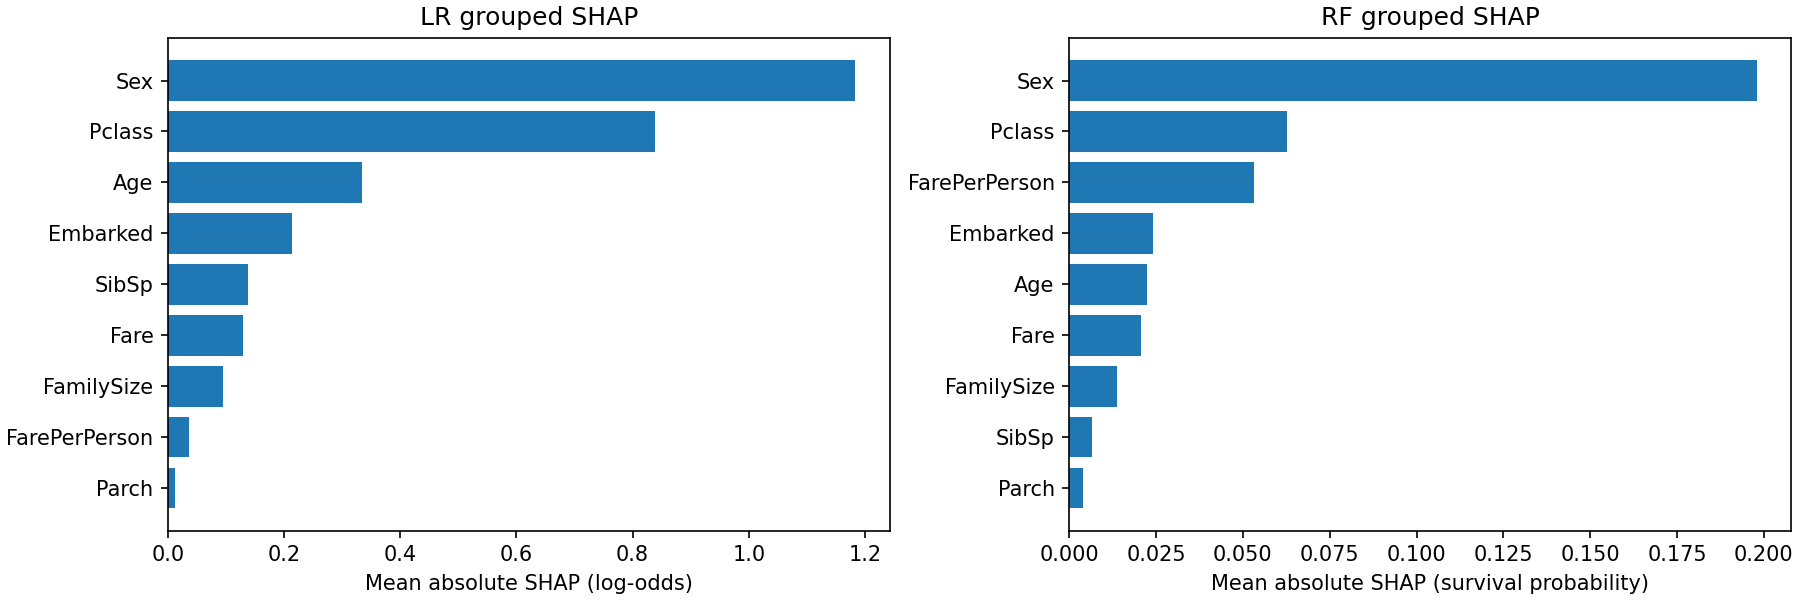

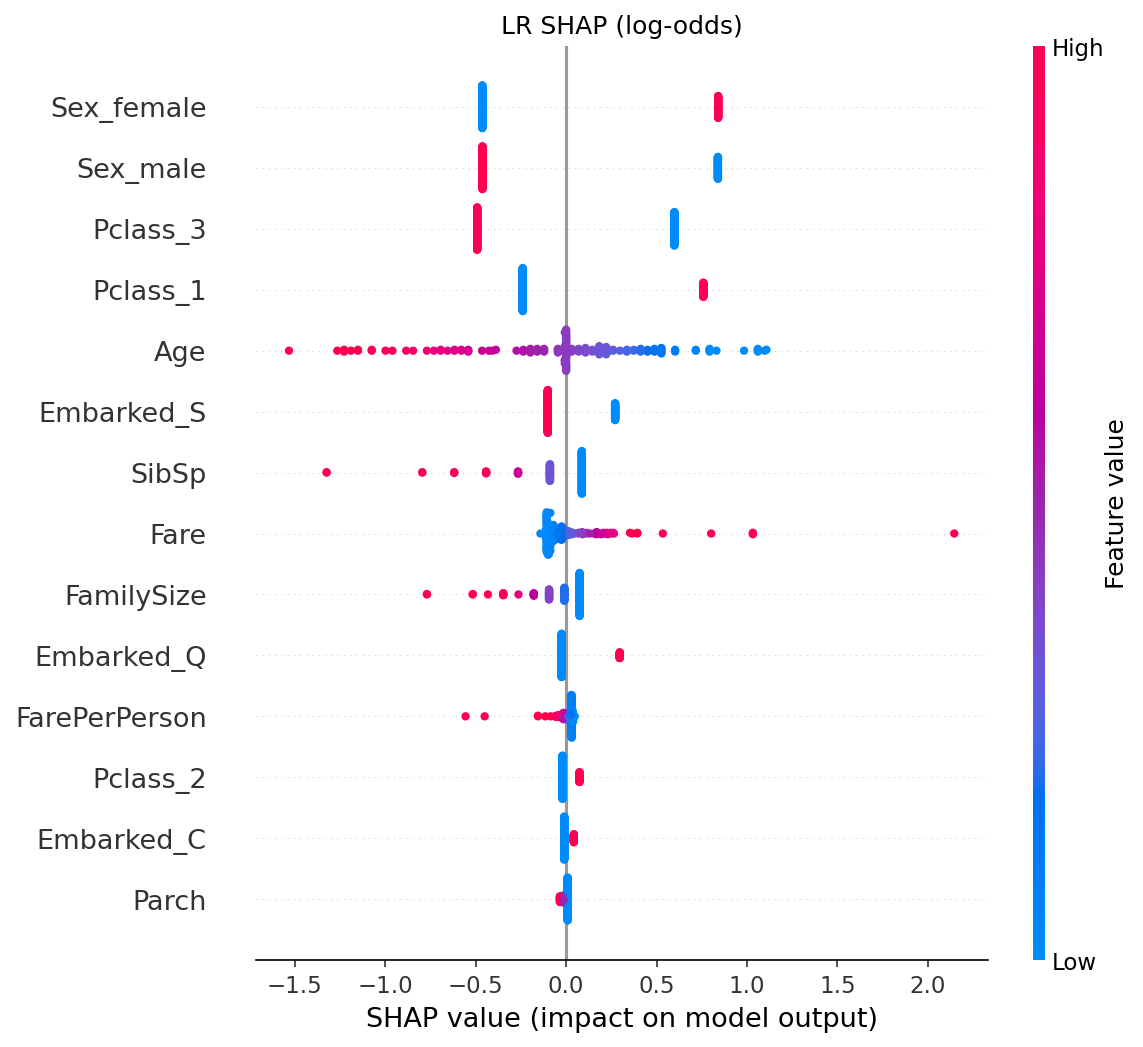

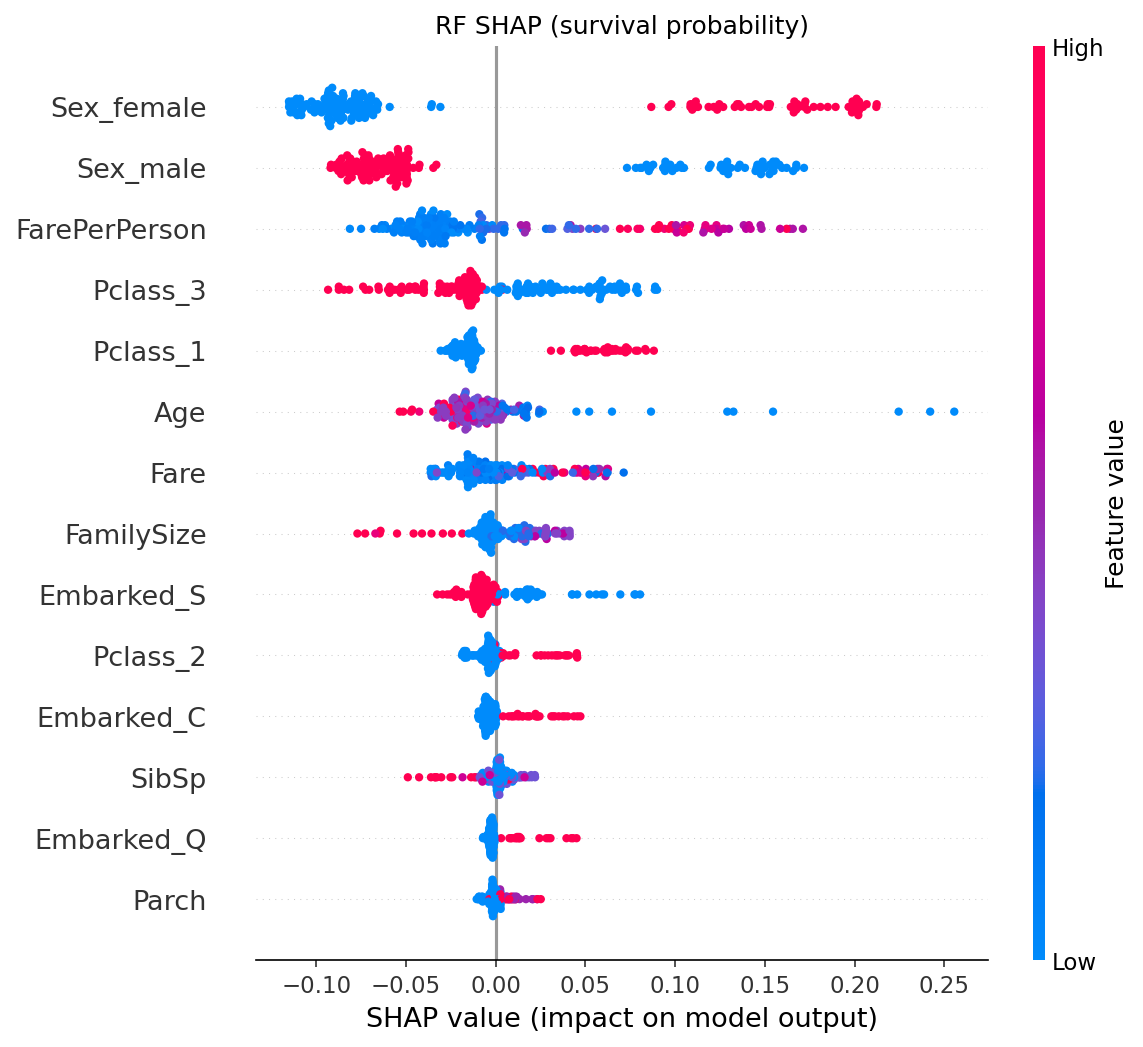

LR 상위 3개: Sex, Pclass, Age
RF 상위 3개: Sex, Pclass, FarePerPerson
공통 상위 변수: Pclass, Sex
One-Hot 기여도는 승객별로 원래 변수에 합산한 뒤 절댓값 평균을 계산했습니다.
양의 SHAP는 생존 예측을 높이고 음의 SHAP는 낮춥니다. 상관 변수의 기여도는 배경 분포 가정에 영향을 받으며 인과 효과를 뜻하지 않습니다.


In [10]:
def shap_analysis(train, train_y, test, final, out):
    """Explain LR log-odds and RF survival probabilities with the actual SHAP library."""
    import shap
    import matplotlib.pyplot as plt

    lr = make_pipeline("Exp-1", "LR").fit(train, train_y)
    rf_is_final = isinstance(final.named_steps["model"], RandomForestClassifier)
    rf = final if rf_is_final else make_pipeline("Exp-1", "RF").fit(train, train_y)
    result = {"version": shap.__version__, "background": "development data only",
              "explanation_rows": len(test), "models": {}}
    for label, pipeline in (("LR", lr), ("RF", rf)):
        matrix = np.asarray(pipeline[:-1].transform(test), dtype=float)
        background = np.asarray(pipeline[:-1].transform(train), dtype=float)
        names = pipeline.named_steps["columns"].get_feature_names_out()
        selector = pipeline.named_steps.get("select", "passthrough")
        if selector != "passthrough":
            names = names[selector.get_support()]
        model = pipeline.named_steps["model"]
        explanation_method = "LinearExplainer"
        tree_additivity_error = None
        if label == "LR":
            masker = shap.maskers.Independent(background, max_samples=len(background))
            explainer = shap.LinearExplainer(model, masker)
            values = np.asarray(explainer.shap_values(matrix))
            expected = float(np.asarray(explainer.expected_value).item())
            prediction = model.decision_function(matrix)
            unit = "log-odds"
        else:
            # sklearn forests predict using float32; keep background and explained rows aligned.
            matrix = np.asarray(matrix, dtype=np.float32)
            background = np.asarray(background, dtype=np.float32)
            background = shap.sample(background, min(100, len(background)), random_state=SEED)
            positive_class = list(model.classes_).index(1)
            def predict_survival(rows):
                return model.predict_proba(np.asarray(rows, dtype=np.float32))[:, positive_class]
            prediction = predict_survival(matrix)
            np.testing.assert_allclose(prediction, pipeline.predict_proba(test)[:, positive_class],
                                       atol=1e-12, rtol=1e-12)
            try:
                explainer = shap.TreeExplainer(model, data=background,
                    feature_perturbation="interventional", model_output="probability")
                raw = explainer.shap_values(matrix, check_additivity=True)
                if isinstance(raw, list):
                    values = np.asarray(raw[positive_class])
                else:
                    raw = np.asarray(raw)
                    values = raw[:, :, positive_class] if raw.ndim == 3 else raw
                expected_values = np.asarray(explainer.expected_value).reshape(-1)
                expected = float(expected_values[positive_class] if len(expected_values) > 1 else expected_values[0])
                tree_additivity_error = float(np.max(np.abs(expected + values.sum(axis=1) - prediction)))
                np.testing.assert_allclose(expected + values.sum(axis=1), prediction, atol=1e-6, rtol=1e-6)
                np.testing.assert_allclose(expected, predict_survival(background).mean(), atol=1e-6, rtol=1e-6)
                explanation_method = "TreeExplainer (interventional)"
            except Exception as error:
                # Recover only from an attribution consistency failure, not arbitrary input/API errors.
                is_additivity_error = (isinstance(error, AssertionError) or
                    (type(error).__name__ == "ExplainerError" and "Additivity check failed" in str(error)))
                if not is_additivity_error:
                    raise
                print(f"RF TreeExplainer reconstruction failed (max error={tree_additivity_error}). "
                      "Recomputing with PermutationExplainer on the same model/output/background.", flush=True)
                masker = shap.maskers.Independent(background, max_samples=len(background))
                explainer = shap.PermutationExplainer(predict_survival, masker,
                    feature_names=list(map(str, names)), seed=SEED)
                explanation = explainer(matrix, max_evals=5 * (2 * matrix.shape[1] + 1),
                                         batch_size=100, silent=False)
                values = np.asarray(explanation.values)
                bases = np.asarray(explanation.base_values).reshape(-1)
                expected = float(predict_survival(background).mean())
                np.testing.assert_allclose(bases, expected, atol=1e-6, rtol=1e-6)
                explanation_method = "PermutationExplainer (5 forward/reverse permutation cycles)"
            unit = "survival probability"
        np.testing.assert_allclose(expected + values.sum(axis=1), prediction, atol=1e-6, rtol=1e-6)
        mean_absolute = dict(zip(map(str, names), map(float, np.abs(values).mean(axis=0))))
        # Combine signed one-hot contributions per passenger before computing absolute importance.
        groups = {}
        for index, name in enumerate(names):
            origin = next((cat for cat in CAT if name.startswith(cat + "_")), str(name))
            groups.setdefault(origin, []).append(index)
        grouped = {name: float(np.abs(values[:, indices].sum(axis=1)).mean())
                   for name, indices in groups.items()}
        result["models"][label] = {"unit": unit, "expected_value": expected,
            "explainer": explanation_method, "rejected_tree_max_error": tree_additivity_error,
            "background_rows": len(background), "mean_absolute": mean_absolute,
            "grouped_mean_absolute": grouped,
            "additivity_max_error": float(np.max(np.abs(expected + values.sum(axis=1) - prediction))),
            "pipeline": "Exp-1 / LR" if label == "LR" else ("final tuned RF" if rf_is_final else "Exp-1 / RF")}
        np.savez_compressed(out / f"shap_{label.lower()}_values.npz", values=values,
                            features=matrix, names=np.asarray(names, dtype=str), expected=expected)
        shap.summary_plot(values, matrix, feature_names=names, show=False, max_display=14)
        plt.title(f"{label} SHAP ({unit})")
        plt.tight_layout()
        plt.savefig(out / f"shap_{label.lower()}_beeswarm.png", dpi=150, bbox_inches="tight")
        plt.close("all")
    return result
print('실제 SHAP 분석을 실행합니다.', flush=True)
shap_result = shap_analysis(train, train_y, test, final, RESULTS_DIR)
shap_rows, shap_rankings = [], {}
for label, entry in shap_result['models'].items():
    ranked = sorted(entry['grouped_mean_absolute'].items(), key=lambda kv:kv[1], reverse=True)
    shap_rankings[label] = [name for name, _ in ranked]
    for rank, (name, value) in enumerate(ranked,1):
        shap_rows.append({'모델':label,'순위':rank,'변수':name,'평균 절대 SHAP':value,'단위':entry['unit']})
    print(label, entry['pipeline'], '| 설명기:', entry['explainer'], '| 예측 복원 최대 오차:', entry['additivity_max_error'])
shap_table = pd.DataFrame(shap_rows)
display(shap_table.round(5))
fig, axes = plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax, label in zip(axes,MODELS):
    entry = shap_result['models'][label]
    top = pd.Series(entry['grouped_mean_absolute']).nlargest(9).sort_values()
    ax.barh(top.index,top)
    ax.set(title=f'{label} grouped SHAP',xlabel=f"Mean absolute SHAP ({entry['unit']})")
fig.savefig(RESULTS_DIR / 'shap_comparison.png',dpi=150)
plt.close(fig)
for name in ['shap_comparison.png','shap_lr_beeswarm.png','shap_rf_beeswarm.png']:
    display(Image(filename=str(RESULTS_DIR / name)))
common = sorted(set(shap_rankings['LR'][:3]) & set(shap_rankings['RF'][:3]))
print('LR 상위 3개:', ', '.join(shap_rankings['LR'][:3]))
print('RF 상위 3개:', ', '.join(shap_rankings['RF'][:3]))
print('공통 상위 변수:', ', '.join(common) if common else '없음')
print('One-Hot 기여도는 승객별로 원래 변수에 합산한 뒤 절댓값 평균을 계산했습니다.')
print('양의 SHAP는 생존 예측을 높이고 음의 SHAP는 낮춥니다. 상관 변수의 기여도는 배경 분포 가정에 영향을 받으며 인과 효과를 뜻하지 않습니다.')
shap_table.to_csv(RESULTS_DIR / 'shap_comparison.csv',index=False,encoding='utf-8-sig')


## AutoML 비교 실험

전처리 3종 × 모델 2종 × 파라미터 2종의 총 12개 후보를 자동 탐색합니다.
외부 5겹·내부 3겹 중첩 교차검증으로 평가하고, 사전에 고정한 Exp-1 RF와 동일 외부 폴드로 비교합니다.
범용 AutoML 제품을 사용한 실험이 아니라 직접 구성한 후보 집합의 자동 탐색입니다.


In [11]:
def auto_search(x, y, folds):
    candidates = []
    for experiment, model in product(CORE[1:], MODELS):
        pipeline = make_pipeline(experiment, model)
        if model == "LR":
            candidates.append({"candidate": [pipeline], "candidate__model__C": [1., 5.]})
        else:
            for depth, leaf in ((9, 3), (5, 6)):
                candidates.append({
                    "candidate": [pipeline], "candidate__model__max_depth": [depth],
                    "candidate__model__min_samples_leaf": [leaf],
                })
    search = GridSearchCV(
        Pipeline([("candidate", make_pipeline("Exp-1", "LR"))]), candidates,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
        scoring="roc_auc", error_score="raise",
    )
    scores = cross_validate(search, x, y, cv=folds, scoring=SCORING,
                            return_train_score=True, return_estimator=True, error_score="raise")

    reference = cross_validate(make_pipeline("Exp-1", "RF"), x, y, cv=folds,
                               scoring=SCORING, return_train_score=True, error_score="raise")
    choices = []
    for fitted in scores["estimator"]:
        candidate = fitted.best_estimator_.named_steps["candidate"]
        selected_model = candidate.named_steps["model"]
        configuration = {k: v for k, v in fitted.best_params_.items() if k != "candidate"}
        impute = candidate.named_steps["columns"].named_transformers_["numeric"].named_steps["fill"].strategy
        selected_experiment = {"mean": "Exp-1", "median": "Exp-2", "most_frequent": "Exp-3"}[impute]
        choices.append({"experiment": selected_experiment, "model": type(selected_model).__name__, "parameters": configuration,
                        "inner_best_auc": float(fitted.best_score_)})
    return {"scores": summarize_scores(scores), "reference_scores": summarize_scores(reference),
            "reference": "Exp-1 / RF (fixed in advance)", "outer_folds": 5, "inner_folds": 3,
            "candidate_count": 12, "choices": choices,
            "outer_auc": list(map(float, scores["test_roc_auc"])),
            "reference_outer_auc": list(map(float, reference["test_roc_auc"])),
            "paired_auc_delta": list(map(float, scores["test_roc_auc"] - reference["test_roc_auc"]))}
print('AutoML 중첩 교차검증을 실행합니다.', flush=True)
automl = auto_search(train, train_y, folds)
automl_table = pd.DataFrame([
    {'방법':'사전 고정 Exp-1 RF',**automl['reference_scores']},
    {'방법':'제한된 AutoML',**automl['scores']},
])
display(automl_table.round(4))
fold_table = pd.DataFrame({'외부 폴드':range(1,6),'고정 RF AUC':automl['reference_outer_auc'],
    'AutoML AUC':automl['outer_auc'],'차이':automl['paired_auc_delta']})
display(fold_table.round(4))
display(pd.DataFrame(automl['choices']))
auc_change = automl['scores']['roc_auc'] - automl['reference_scores']['roc_auc']
print(f'AutoML 평균 외부 AUC 차이: {auc_change:+.4f}')
print('이 실행에서는 자동 탐색의 평균값이 더 높았습니다.' if auc_change > 0 else '이 실행에서는 자동 탐색이 고정 기준을 넘지 못했습니다.')
automl_table.to_csv(RESULTS_DIR / 'automl_comparison.csv',index=False,encoding='utf-8-sig')
fold_table.to_csv(RESULTS_DIR / 'automl_folds.csv',index=False,encoding='utf-8-sig')


AutoML 중첩 교차검증을 실행합니다.


,방법,accuracy,precision,recall,f1,roc_auc,train_f1,roc_auc_sd,f1_sd
0,사전 고정 Exp-1 RF,0.8287,0.8233,0.7105,0.7616,0.8776,0.8562,0.0233,0.0416
1,제한된 AutoML,0.8188,0.8161,0.6851,0.7431,0.8731,0.8401,0.0321,0.0371


,외부 폴드,고정 RF AUC,AutoML AUC,차이
0,1,0.8683,0.8683,0.0000
1,2,0.8475,0.8296,-0.0179
2,3,0.9086,0.9142,0.0056
3,4,0.8915,0.8924,0.0008
4,5,0.8721,0.8610,-0.0110


,experiment,model,parameters,inner_best_auc
0,Exp-1,RandomForestClassifier,"{'candidate__model__max_depth': 9, 'candidate_...",0.886116
1,Exp-3,RandomForestClassifier,"{'candidate__model__max_depth': 9, 'candidate_...",0.890150
2,Exp-1,RandomForestClassifier,"{'candidate__model__max_depth': 5, 'candidate_...",0.856345
3,Exp-2,RandomForestClassifier,"{'candidate__model__max_depth': 9, 'candidate_...",0.877356
4,Exp-2,RandomForestClassifier,"{'candidate__model__max_depth': 9, 'candidate_...",0.843851


AutoML 평균 외부 AUC 차이: -0.0045
이 실행에서는 자동 탐색이 고정 기준을 넘지 못했습니다.
탐색은 개선을 보장하지 않으며 제한된 후보와 내부 학습 표본 크기에 영향을 받습니다. 통계적 유의성을 검정한 결과는 아닙니다.
외부 CV와 최종 홀드아웃은 서로 다른 평가이므로 두 점수를 직접 개선율로 비교하지 않습니다.


## 최종 결론과 결과 보관

실행 결과로 결론을 출력하고 표·그래프·원본 점수를 ZIP으로 보관합니다.

In [12]:
print(f"필수 조합 중 최고: {winner['experiment']} / {winner['model']}, 검증 AUC {winner['roc_auc']:.4f}")
print('Base와 전체 조합의 비교에는 입력 변수 차이도 포함됩니다.')
print('정수 인코딩으로 변경한 AUC 차이:', {m:round(auc_delta('A-Label',m),4) for m in MODELS})
print('스케일링 변화량:')
display(ablation.loc[['Standard → MinMax','Standard → Robust']].round(4))
print('파생 변수 2개 추가 효과:', {m:round(-auc_delta('A-NoDerived',m),4) for m in MODELS})
helped = selection_comparison[(selection_comparison['선택 후 AUC'] >= selection_comparison['선택 전 AUC']) &
    (selection_comparison['선택 후 F1 격차'] < selection_comparison['선택 전 F1 격차'])]
print('F1 격차가 줄면서 검증 AUC도 유지/개선된 변수 선택 조합:',
      helped[['실험','모델']].to_dict('records') if len(helped) else '없음')
ticket_overlap = len(set(data.loc[train.index,'Ticket']) & set(data.loc[test.index,'Ticket']))
print('개발/평가에 공통인 Ticket:',ticket_overlap,'개. 승선권 그룹 단위 평가에서는 결과가 달라질 수 있습니다.')
summary = {'shape':list(data.shape),'split_sizes':[len(train),len(test)],
    'selections':selections,'winner':winner.to_dict(),'best_params':search.best_params_,
    'holdout':holdout,'shap_analysis':shap_result,'automl':automl,'outliers':outliers,
    'ticket_overlap':ticket_overlap,'data_sha256':hashlib.sha256(contents).hexdigest(),
    'environment':{'python':platform.python_version(),'numpy':np.__version__,
        'pandas':pd.__version__,'scikit-learn':sklearn.__version__,
        'matplotlib':matplotlib.__version__,'shap':shap.__version__}}
(RESULTS_DIR / 'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
pd.DataFrame({'row':train.index}).to_csv(RESULTS_DIR / 'eda_rows.csv',index=False)
selection_comparison.to_csv(RESULTS_DIR / 'selection_comparison.csv',index=False,encoding='utf-8-sig')
ablation.to_csv(RESULTS_DIR / 'ablation_comparison.csv',encoding='utf-8-sig')
import zipfile
bundle = RUN_DIR / 'titanic-results.zip'
with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as archive:
    for file in RESULTS_DIR.rglob('*'):
        if file.is_file():
            archive.write(file,file.relative_to(RESULTS_DIR))
files.download(str(bundle))


필수 조합 중 최고: Exp-1 / RF, 검증 AUC 0.8776
Base와 전체 조합의 비교에는 입력 변수 차이도 포함됩니다.
정수 인코딩으로 변경한 AUC 차이: {'LR': np.float64(-0.0007), 'RF': np.float64(0.0012)}
스케일링 변화량:


,LR,RF
Standard → MinMax,0.0002,-0.0003
Standard → Robust,-0.0004,0.0004


파생 변수 2개 추가 효과: {'LR': np.float64(0.0002), 'RF': np.float64(0.0048)}
F1 격차가 줄면서 검증 AUC도 유지/개선된 변수 선택 조합: 없음
개발/평가에 공통인 Ticket: 61 개. 승선권 그룹 단위 평가에서는 결과가 달라질 수 있습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>